  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.6 MB/s eta 0:00:00
Mounted at /content/drive
Train shape: (231, 6)
Val shape  : (27, 6)
Test shape : (27, 6)


,compound,sentence_type,sentence,image_name,image_caption,label
0,hot potato,idiomatic,The pipeline is set to create a human rights d...,46916305307.png,The image depicts two cartoon-style characters...,1
1,hot potato,idiomatic,The pipeline is set to create a human rights d...,00316911039.png,The image depicts an oven with a large potato ...,0
2,hot potato,idiomatic,The pipeline is set to create a human rights d...,71196374341.png,"The image depicts an old, rolled-up parchment ...",0
3,act of god,idiomatic,"Whether an event is intentional, accidental or...",80127117511.png,The image depicts a scene where a large tree h...,1
4,act of god,idiomatic,"Whether an event is intentional, accidental or...",51312988406.png,The image depicts a whimsical scene featuring ...,0


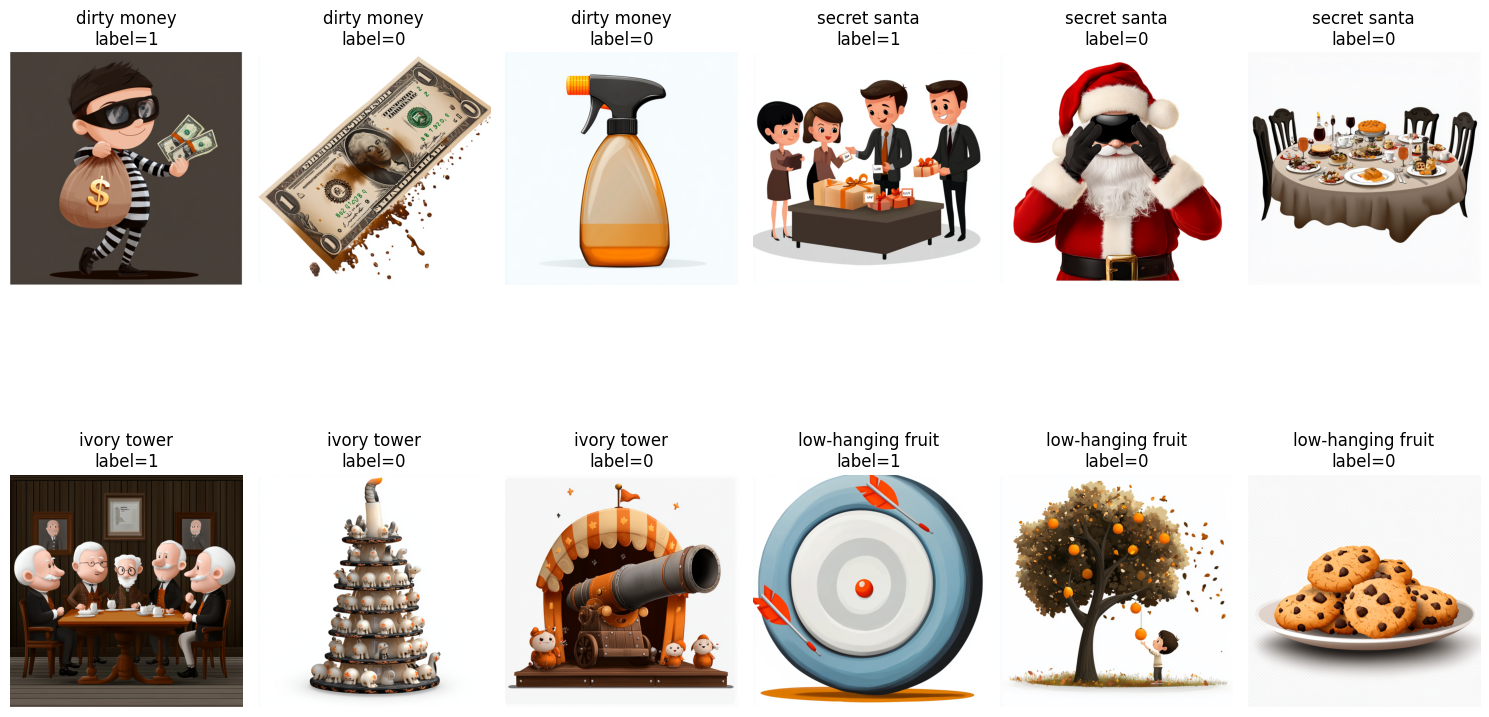


===== TRAIN: GROUP STRUCTURE CHECK =====
Group size distribution:
3    77
Name: count, dtype: int64

Positive labels per group:
label
1    77
Name: count, dtype: int64

Groups not of size 3: 0
Groups not having exactly 1 positive: 0

===== VAL: GROUP STRUCTURE CHECK =====
Group size distribution:
3    9
Name: count, dtype: int64

Positive labels per group:
label
1    9
Name: count, dtype: int64

Groups not of size 3: 0
Groups not having exactly 1 positive: 0

===== TEST: GROUP STRUCTURE CHECK =====
Group size distribution:
3    9
Name: count, dtype: int64

Positive labels per group:
label
1    9
Name: count, dtype: int64

Groups not of size 3: 0
Groups not having exactly 1 positive: 0


In [1]:
#Install packages
%pip install -q git+https://github.com/openai/CLIP.git
%pip install -q torch torchvision transformers sentencepiece accelerate
%pip install -q numpy pandas scikit-learn matplotlib seaborn pillow joblib tqdm

#Imports
import os
import gc
import re
import joblib
import torch
import clip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from PIL import Image
from tqdm import tqdm
from google.colab import drive, files

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    BlipProcessor,
    BlipForConditionalGeneration
)

# Mount drive
from google.colab import drive
drive.mount('/content/drive')

# Paths
fpath = "/content/drive/MyDrive/AAI/Task2/"

train_path = os.path.join(fpath, "train", "train.csv")
val_path   = os.path.join(fpath, "val", "val.csv")
test_path  = os.path.join(fpath, "test", "test.csv")

train_img_dir = os.path.join(fpath, "train", "images")
val_img_dir   = os.path.join(fpath, "val", "images")
test_img_dir  = os.path.join(fpath, "test", "images")

# Load CSVs
train_df = pd.read_csv(train_path)
val_df   = pd.read_csv(val_path)
test_df  = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Val shape  :", val_df.shape)
print("Test shape :", test_df.shape)

display(train_df.head())

# Basic visualisation helper
def visualise_data(df, image_folder, n_rows=2):
    n = min(len(df), n_rows * 6)
    sample_df = df.head(n).copy()

    fig, axes = plt.subplots(n_rows, 6, figsize=(15, 5 * n_rows))
    axes = axes.flatten()

    for idx, (_, row) in enumerate(sample_df.iterrows()):
        image_path = os.path.join(image_folder, row["image_name"])
        try:
            img = Image.open(image_path).convert("RGB")
            axes[idx].imshow(img)
            axes[idx].set_title(f"{row['compound']}\nlabel={row['label']}")
            axes[idx].axis("off")
        except Exception as e:
            axes[idx].axis("off")
            print(f"Error loading {image_path}: {e}")

    for idx in range(len(sample_df), len(axes)):
        axes[idx].axis("off")

    plt.tight_layout()
    plt.show()

# Example
visualise_data(test_df, test_img_dir, n_rows=2)

# Shared evaluation utilities
group_cols = ["compound", "sentence"]

def verify_group_structure(df, group_cols, name="DATA"):
    group_sizes = df.groupby(group_cols).size()
    positive_counts = df.groupby(group_cols)["label"].sum()

    print(f"\n===== {name}: GROUP STRUCTURE CHECK =====")
    print("Group size distribution:")
    print(group_sizes.value_counts().sort_index())

    print("\nPositive labels per group:")
    print(positive_counts.value_counts().sort_index())

    bad_size = group_sizes[group_sizes != 3]
    bad_pos = positive_counts[positive_counts != 1]

    print(f"\nGroups not of size 3: {len(bad_size)}")
    print(f"Groups not having exactly 1 positive: {len(bad_pos)}")

def evaluate_predictions(df, group_cols, name="SET"):
    acc  = accuracy_score(df["label"], df["prediction"])
    prec = precision_score(df["label"], df["prediction"], zero_division=0)
    rec  = recall_score(df["label"], df["prediction"], zero_division=0)
    f1   = f1_score(df["label"], df["prediction"], zero_division=0)

    group_correct = df.groupby(group_cols).apply(
        lambda g: int(g.loc[g["prediction"].idxmax(), "label"] == 1)
    )
    group_acc = group_correct.mean()

    print(f"\n===== {name} RESULTS =====")
    print(f"Row Accuracy   : {acc:.4f}")
    print(f"Precision      : {prec:.4f}")
    print(f"Recall         : {rec:.4f}")
    print(f"F1 Score       : {f1:.4f}")
    print(f"Group Accuracy : {group_acc:.4f}")

    print("\nClassification report:")
    print(classification_report(df["label"], df["prediction"], digits=4, zero_division=0))

    return {
        "row_accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "group_accuracy": group_acc
    }

def rank_predictions(df, probs, score_col="score"):
    out = df.copy().reset_index(drop=True)
    out[score_col] = probs
    out["prediction"] = 0

    for gid, group in out.groupby("group_id"):
        idxs = group.index.tolist()
        scores = group[score_col].values
        best_idx = idxs[np.argmax(scores)]
        out.loc[best_idx, "prediction"] = 1

    return out

verify_group_structure(train_df, group_cols, "TRAIN")
verify_group_structure(val_df, group_cols, "VAL")
verify_group_structure(test_df, group_cols, "TEST")


TRAIN OVERVIEW
Shape: (231, 6)

Columns:
['compound', 'sentence_type', 'sentence', 'image_name', 'image_caption', 'label']

Missing values:
compound         0
sentence_type    0
sentence         0
image_name       0
image_caption    0
label            0
dtype: int64

VAL OVERVIEW
Shape: (27, 6)

Columns:
['compound', 'sentence_type', 'sentence', 'image_name', 'image_caption', 'label']

Missing values:
compound         0
sentence_type    0
sentence         0
image_name       0
image_caption    0
label            0
dtype: int64

TEST OVERVIEW
Shape: (27, 6)

Columns:
['compound', 'sentence_type', 'sentence', 'image_name', 'image_caption', 'label']

Missing values:
compound         0
sentence_type    0
sentence         0
image_name       0
image_caption    0
label            0
dtype: int64

TRAIN LABEL DISTRIBUTION
label
0    154
1     77
Name: count, dtype: int64

Positive ratio: 0.3333

VAL LABEL DISTRIBUTION
label
0    18
1     9
Name: count, dtype: int64

Positive ratio: 0.3333

TEST

,image_name,image_caption,label
0,46916305307.png,The image depicts two cartoon-style characters...,1
1,00316911039.png,The image depicts an oven with a large potato ...,0
2,71196374341.png,"The image depicts an old, rolled-up parchment ...",0



Compound: act of god
Sentence: Whether an event is intentional, accidental or an act of God, knowing how to properly respond when a crisis occurs in the workplace is critical.


,image_name,image_caption,label
3,80127117511.png,The image depicts a scene where a large tree h...,1
4,51312988406.png,The image depicts a whimsical scene featuring ...,0
5,25535728219.png,The image depicts a vintage-style portable rad...,0



Compound: chicken feed
Sentence: In comparison, the $2 billion spent on transit expansion is chicken feed.


,image_name,image_caption,label
6,26714529074.png,The image shows a hand holding two coins. The ...,1
7,30913213178.png,The image depicts two cartoon-style chickens s...,0
8,43154236098.png,The image depicts a lizard standing on a rock ...,0



Compound: thin ice
Sentence: Investors in both instances were already tiptoeing on thin ice, knowing that the longest US stock market bull run in history was showing signs of overheating.


,image_name,image_caption,label
9,66964681897.png,"The image depicts a person climbing a steep, r...",1
10,38172236941.png,The image depicts the lower half of a person s...,0
11,68101243143.png,The image depicts a dessert dish presented on ...,0



Compound: eager beaver
Sentence: My staff and I were hungry to get young eager beaver staffers to provide daily copy to fill the page devoted to the world of Utah sports.


,image_name,image_caption,label
12,97713215186.png,The image depicts a cartoon-style illustration...,1
13,51848512303.png,The image depicts three cartoon-style beavers ...,0
14,25688411798.png,The image depicts a cartoon-style illustration...,0


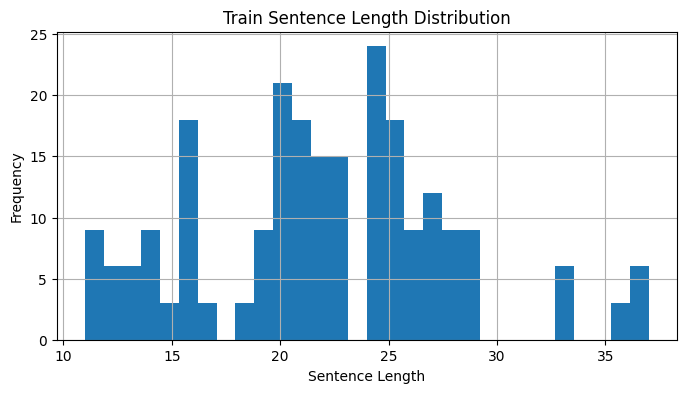

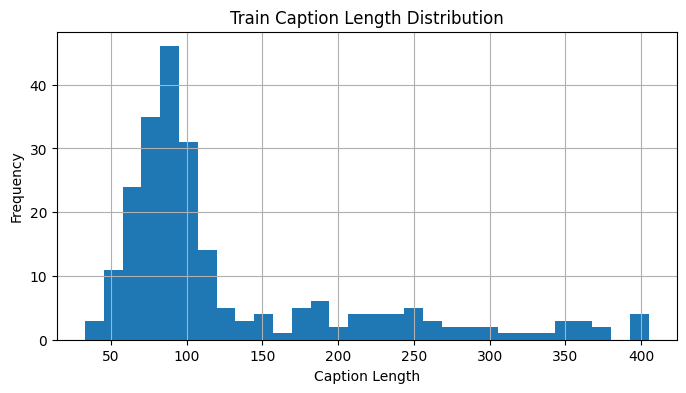


STEP 1 SUMMARY

Key things to check:
1. Each (compound, sentence) group should have 3 candidates.
2. Each group should have exactly 1 positive label.
3. Row-level class imbalance is expected (1 positive, 2 negatives).
4. Captions and sentences may have weak or partial lexical overlap.
5. Repeated compounds motivate contextual modelling.
6. Literal vs idiomatic meaning motivates multimodal methods.



In [2]:
# NLP EDA

train_eda = train_df.copy()
val_eda   = val_df.copy()
test_eda  = test_df.copy()

def dataset_overview(df, name):
    print(f"\n{'='*80}")
    print(f"{name} OVERVIEW")
    print(f"{'='*80}")
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())
    print("\nMissing values:")
    print(df.isnull().sum())

def label_stats(df, name):
    print(f"\n{'='*80}")
    print(f"{name} LABEL DISTRIBUTION")
    print(f"{'='*80}")
    print(df["label"].value_counts().sort_index())
    print("\nPositive ratio:", round(df["label"].mean(), 4))

def add_length_features(df):
    out = df.copy()
    out["compound_len"] = out["compound"].astype(str).apply(lambda x: len(x.split()))
    out["sentence_len"] = out["sentence"].astype(str).apply(lambda x: len(x.split()))
    out["caption_len"]  = out["image_caption"].astype(str).apply(lambda x: len(x.split()))
    return out

def length_stats(df, name):
    print(f"\n{'='*80}")
    print(f"{name} TEXT LENGTH STATS")
    print(f"{'='*80}")
    print("\nCompound length:")
    print(df["compound_len"].describe())
    print("\nSentence length:")
    print(df["sentence_len"].describe())
    print("\nCaption length:")
    print(df["caption_len"].describe())

def show_top_compounds(df, name, top_n=15):
    print(f"\n{'='*80}")
    print(f"{name} TOP {top_n} COMPOUNDS")
    print(f"{'='*80}")
    print(df["compound"].value_counts().head(top_n))

def group_summary(df, group_cols, name):
    group_sizes = df.groupby(group_cols).size()
    pos_counts  = df.groupby(group_cols)["label"].sum()

    print(f"\n{'='*80}")
    print(f"{name} GROUP SUMMARY")
    print(f"{'='*80}")
    print("\nNumber of unique groups:", len(group_sizes))
    print("\nGroup size distribution:")
    print(group_sizes.value_counts().sort_index())
    print("\nPositive labels per group:")
    print(pos_counts.value_counts().sort_index())

def tokenize(text):
    return set(re.findall(r"\b\w+\b", str(text).lower()))

def overlap_ratio(a, b):
    a_tokens = tokenize(a)
    b_tokens = tokenize(b)
    if len(a_tokens) == 0:
        return 0.0
    return len(a_tokens & b_tokens) / len(a_tokens)

def add_overlap_features(df):
    out = df.copy()
    out["sentence_caption_overlap"] = out.apply(
        lambda r: overlap_ratio(r["sentence"], r["image_caption"]), axis=1
    )
    out["compound_caption_overlap"] = out.apply(
        lambda r: overlap_ratio(r["compound"], r["image_caption"]), axis=1
    )
    return out

def overlap_stats(df, name):
    print(f"\n{'='*80}")
    print(f"{name} OVERLAP STATS BY LABEL")
    print(f"{'='*80}")
    print("\nSentence ↔ Caption overlap:")
    print(df.groupby("label")["sentence_caption_overlap"].describe())
    print("\nCompound ↔ Caption overlap:")
    print(df.groupby("label")["compound_caption_overlap"].describe())

def inspect_groups(df, group_cols, n_groups=5):
    groups = df[group_cols].drop_duplicates().head(n_groups)
    for _, g in groups.iterrows():
        mask = np.logical_and.reduce([df[c] == g[c] for c in group_cols])
        group_df = df[mask].copy()

        print("\n" + "="*100)
        print("Compound:", group_df.iloc[0]["compound"])
        print("Sentence:", group_df.iloc[0]["sentence"])
        print("="*100)
        display(group_df[["image_name", "image_caption", "label"]])

dataset_overview(train_eda, "TRAIN")
dataset_overview(val_eda, "VAL")
dataset_overview(test_eda, "TEST")

label_stats(train_eda, "TRAIN")
label_stats(val_eda, "VAL")
label_stats(test_eda, "TEST")

train_eda = add_length_features(train_eda)
val_eda   = add_length_features(val_eda)
test_eda  = add_length_features(test_eda)

length_stats(train_eda, "TRAIN")
length_stats(val_eda, "VAL")
length_stats(test_eda, "TEST")

show_top_compounds(train_eda, "TRAIN", top_n=15)

group_summary(train_eda, group_cols, "TRAIN")
group_summary(val_eda, group_cols, "VAL")
group_summary(test_eda, group_cols, "TEST")

train_eda = add_overlap_features(train_eda)
val_eda   = add_overlap_features(val_eda)
test_eda  = add_overlap_features(test_eda)

overlap_stats(train_eda, "TRAIN")
inspect_groups(train_eda, group_cols, n_groups=5)

plt.figure(figsize=(8, 4))
train_eda["sentence_len"].hist(bins=30)
plt.title("Train Sentence Length Distribution")
plt.xlabel("Sentence Length")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(8, 4))
train_eda["caption_len"].hist(bins=30)
plt.title("Train Caption Length Distribution")
plt.xlabel("Caption Length")
plt.ylabel("Frequency")

In [3]:
# LLM BASED DATA AUGMENTATION

group_cols = ["compound", "sentence"]
step2_dir = os.path.join(fpath, "results_step2_llm_augmentation")
os.makedirs(step2_dir, exist_ok=True)

train_groups = train_df[group_cols].drop_duplicates().copy().reset_index(drop=True)
train_groups["group_id"] = range(1, len(train_groups) + 1)

print("Number of unique training groups:", len(train_groups))
display(train_groups.head())

device = "cuda" if torch.cuda.is_available() else "cpu"
model_name = "google/flan-t5-base" if device == "cuda" else "google/flan-t5-small"

print("Using device:", device)
print("Loading augmentation model:", model_name)

aug_tokenizer = AutoTokenizer.from_pretrained(model_name)
aug_model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device)
aug_model.eval()

def build_paraphrase_prompt(compound, sentence):
    return (
        "Paraphrase the sentence while preserving the intended meaning of the idiom in context. "
        "Keep it natural and concise.\n\n"
        f"Compound: {compound}\n"
        f"Sentence: {sentence}\n\n"
        "Paraphrase:"
    )

def build_gloss_prompt(compound, sentence):
    return (
        "Explain the meaning of the compound in this sentence using one short phrase only. "
        "Do not repeat the full sentence.\n\n"
        f"Compound: {compound}\n"
        f"Sentence: {sentence}\n\n"
        "Meaning:"
    )

@torch.no_grad()
def generate_text(prompts, max_new_tokens=40, batch_size=8):
    outputs = []
    for i in tqdm(range(0, len(prompts), batch_size), desc="Generating"):
        batch_prompts = prompts[i:i+batch_size]
        inputs = aug_tokenizer(
            batch_prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=256
        ).to(device)

        generated = aug_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            num_beams=4,
            do_sample=False,
            early_stopping=True
        )

        batch_outputs = aug_tokenizer.batch_decode(generated, skip_special_tokens=True)
        outputs.extend([x.strip() for x in batch_outputs])

        del inputs, generated
        if device == "cuda":
            torch.cuda.empty_cache()
    return outputs

def clean_text(x):
    x = str(x).strip().replace("\n", " ")
    x = " ".join(x.split())
    return x

paraphrase_prompts = [
    build_paraphrase_prompt(row["compound"], row["sentence"])
    for _, row in train_groups.iterrows()
]

gloss_prompts = [
    build_gloss_prompt(row["compound"], row["sentence"])
    for _, row in train_groups.iterrows()
]

train_groups["sentence_aug"] = generate_text(
    paraphrase_prompts,
    max_new_tokens=48,
    batch_size=8 if device == "cuda" else 4
)

train_groups["idiom_gloss"] = generate_text(
    gloss_prompts,
    max_new_tokens=20,
    batch_size=8 if device == "cuda" else 4
)

train_groups["sentence_aug"] = train_groups["sentence_aug"].apply(clean_text)
train_groups["idiom_gloss"] = train_groups["idiom_gloss"].apply(clean_text)

train_groups["sentence_aug"] = train_groups.apply(
    lambda r: r["sentence"] if r["sentence_aug"] == "" else r["sentence_aug"],
    axis=1
)
train_groups["idiom_gloss"] = train_groups["idiom_gloss"].replace("", "idiomatic meaning in context")

def normalize_text(x):
    x = str(x).strip().lower()
    x = re.sub(r"\s+", " ", x)
    return x

def gloss_is_bad(gloss, sentence):
    g = normalize_text(gloss)
    s = normalize_text(sentence)

    if len(g.split()) < 3:
        return True
    if len(g.split()) > 18:
        return True
    if g == s:
        return True
    if g in s or s in g:
        return True

    bad_phrases = [
        "is a type of precipitation",
        "the sentence means",
        "the compound means the sentence",
    ]
    return any(bp in g for bp in bad_phrases)

def sentence_aug_is_bad(sentence_aug, sentence):
    sa = normalize_text(sentence_aug)
    s = normalize_text(sentence)
    if sa == s:
        return True
    if len(sa.split()) < 6:
        return True
    return False

train_groups["sentence_aug_bad"] = train_groups.apply(
    lambda r: sentence_aug_is_bad(r["sentence_aug"], r["sentence"]),
    axis=1
)

train_groups["idiom_gloss_bad"] = train_groups.apply(
    lambda r: gloss_is_bad(r["idiom_gloss"], r["sentence"]),
    axis=1
)

train_groups["has_llm_aug"] = ~(
    train_groups["sentence_aug_bad"] | train_groups["idiom_gloss_bad"]
)

print("\nFiltered LLM augmentation coverage:")
print(train_groups["has_llm_aug"].value_counts(dropna=False))
print("Coverage ratio:", round(train_groups["has_llm_aug"].mean(), 4))

display(
    train_groups[
        ["compound", "sentence", "sentence_aug", "idiom_gloss", "has_llm_aug"]
    ].head(10)
)

train_aug_base = train_df.merge(
    train_groups[group_cols + ["group_id", "sentence_aug", "idiom_gloss", "has_llm_aug"]],
    on=group_cols,
    how="left"
)

train_original = train_aug_base.copy()
train_original["augmentation_type"] = "original"

train_llm_aug = train_aug_base[train_aug_base["has_llm_aug"] == True].copy()
train_llm_aug["augmentation_type"] = "llm_augmented"

train_augmented_df = pd.concat([train_original, train_llm_aug], ignore_index=True)

print("Original rows:", len(train_original))
print("LLM rows kept:", len(train_llm_aug))
print("Final dataset:", len(train_augmented_df))

group_level_path = os.path.join(step2_dir, "group_level_llm_augments_generated.csv")
train_aug_path = os.path.join(step2_dir, "train_augmented_llm.csv")

train_groups.to_csv(group_level_path, index=False)
train_augmented_df.to_csv(train_aug_path, index=False)

print("\nSaved files:")
print(group_level_path)
print(train_aug_path)

gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

Number of unique training groups: 77


,compound,sentence,group_id
0,hot potato,The pipeline is set to create a human rights d...,1
1,act of god,"Whether an event is intentional, accidental or...",2
2,chicken feed,"In comparison, the $2 billion spent on transit...",3
3,thin ice,Investors in both instances were already tipto...,4
4,eager beaver,My staff and I were hungry to get young eager ...,5


Using device: cuda
Loading augmentation model: google/flan-t5-base


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

... (7 outputs left out)

Generating: 100%|██████████| 10/10 [00:01<00:00,  5.69it/s]


Filtered LLM augmentation coverage:
has_llm_aug
False    76
True      1
Name: count, dtype: int64
Coverage ratio: 0.013


,compound,sentence,sentence_aug,idiom_gloss,has_llm_aug
0,hot potato,The pipeline is set to create a human rights d...,The pipeline is set to create a human rights d...,hot potato,False
1,act of god,"Whether an event is intentional, accidental or...","Whether an event is intentional, accidental or...",act of god,False
2,chicken feed,"In comparison, the $2 billion spent on transit...","In comparison, $2 billion spent on transit exp...",chicken feed,False
3,thin ice,Investors in both instances were already tipto...,Investors were already tiptoeing on thin ice k...,thin ice,False
4,eager beaver,My staff and I were hungry to get young eager ...,My staff and I were hungry to get young eager ...,eager beaver,False
5,big cheese,I've just spent a week trawling round Silicon ...,I've just spent a week trawling round Silicon ...,big cheese,False
6,old flame,She ran into an old flame at the high school r...,She ran into an old flame at a high school reu...,an old flame,False
7,nest egg,Some would be better off with no insurance and...,Some would be better off with no insurance and...,nest egg,False
8,hen party,You can spot the hen parties easily because th...,You can spot the hen parties easily because th...,they always dress in stupid outfits,False
9,pins and needles,Everyone can get pins and needles but see a GP...,Everyone can get pins and needles but see a GP...,it lasts,False


Original rows: 231
LLM rows kept: 3
Final dataset: 234

Saved files:
/content/drive/MyDrive/AAI/Task2/results_step2_llm_augmentation/group_level_llm_augments_generated.csv
/content/drive/MyDrive/AAI/Task2/results_step2_llm_augmentation/train_augmented_llm.csv


In [4]:
# ZERO-SHOT PREDICTION USING CLIP

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)
clip_model.eval()

test_zs = test_df.copy()
test_zs["group_id"] = test_zs.groupby(group_cols).ngroup()

def safe_str(x):
    if pd.isna(x):
        return ""
    return str(x).strip()

def build_context_prompt(row):
    compound = safe_str(row["compound"])
    sentence = safe_str(row["sentence"])
    return (
        f"The compound '{compound}' is used in this sentence: {sentence}. "
        f"Choose the image that matches the intended meaning in context."
    )

def build_gloss_prompt(row):
    compound = safe_str(row["compound"])
    sentence = safe_str(row["sentence"])
    return (
        f"In this sentence, the phrase '{compound}' should be interpreted by meaning, "
        f"not just literal words: {sentence}."
    )

@torch.no_grad()
def encode_texts(texts):
    tokens = clip.tokenize(texts, truncate=True).to(device)
    feats = clip_model.encode_text(tokens)
    feats = feats / feats.norm(dim=-1, keepdim=True)
    return feats

@torch.no_grad()
def encode_image_clip(image_path):
    image = Image.open(image_path).convert("RGB")
    image_tensor = clip_preprocess(image).unsqueeze(0).to(device)
    feats = clip_model.encode_image(image_tensor)
    feats = feats / feats.norm(dim=-1, keepdim=True)
    return feats

def score_group_zero_shot(group_df, image_folder,
                          w_img_ctx=0.40,
                          w_cap_ctx=0.20,
                          w_img_gloss=0.25,
                          w_cap_gloss=0.15):
    row0 = group_df.iloc[0]

    context_prompt = build_context_prompt(row0)
    gloss_prompt = build_gloss_prompt(row0)

    prompt_feats = encode_texts([context_prompt, gloss_prompt])
    context_feat = prompt_feats[0:1]
    gloss_feat = prompt_feats[1:2]

    scores = []

    for _, row in group_df.iterrows():
        caption = safe_str(row["image_caption"])
        image_path = os.path.join(image_folder, row["image_name"])

        try:
            image_feat = encode_image_clip(image_path)
            caption_feat = encode_texts([caption])

            img_ctx_score   = (image_feat @ context_feat.T).item()
            cap_ctx_score   = (caption_feat @ context_feat.T).item()
            img_gloss_score = (image_feat @ gloss_feat.T).item()
            cap_gloss_score = (caption_feat @ gloss_feat.T).item()

            final_score = (
                w_img_ctx   * img_ctx_score +
                w_cap_ctx   * cap_ctx_score +
                w_img_gloss * img_gloss_score +
                w_cap_gloss * cap_gloss_score
            )

        except Exception as e:
            print(f"Error processing {row['image_name']}: {e}")
            final_score = -1.0

        scores.append(final_score)

    return scores

def zero_shot_predict_clip_fusion(df, image_folder):
    out = df.copy().reset_index(drop=True)
    out["clip_score"] = 0.0
    out["prediction"] = 0

    for gid, group in out.groupby("group_id", sort=True):
        group_indices = group.index.tolist()
        group_scores = score_group_zero_shot(group, image_folder)

        for idx, score in zip(group_indices, group_scores):
            out.at[idx, "clip_score"] = score

        best_idx = group_indices[int(np.argmax(group_scores))]
        out.at[best_idx, "prediction"] = 1

    return out

test_zero_shot = zero_shot_predict_clip_fusion(test_zs, test_img_dir)

test_metrics_zero_shot = evaluate_predictions(
    test_zero_shot,
    group_cols=group_cols,
    name="ZERO-SHOT TEST"
)

print("\n===== IMPROVED ZERO-SHOT RESULTS =====")
for k, v in test_metrics_zero_shot.items():
    print(f"{k}: {v:.4f}")

def show_zero_shot_examples(df_pred, n_groups=3):
    shown = 0
    for gid, group in df_pred.groupby("group_id", sort=True):
        if shown >= n_groups:
            break

        group = group.sort_values("clip_score", ascending=False)

        print("\n" + "=" * 100)
        print("Compound:", group.iloc[0]["compound"])
        print("Sentence:", group.iloc[0]["sentence"])
        print("=" * 100)

        display(group[["image_name", "image_caption", "label", "clip_score", "prediction"]])
        shown += 1

show_zero_shot_examples(test_zero_shot, n_groups=3)

Using device: cuda


100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 279MiB/s]



===== ZERO-SHOT TEST RESULTS =====
Row Accuracy   : 0.4074
Precision      : 0.1111
Recall         : 0.1111
F1 Score       : 0.1111
Group Accuracy : 0.1111

Classification report:
              precision    recall  f1-score   support

           0     0.5556    0.5556    0.5556        18
           1     0.1111    0.1111    0.1111         9

    accuracy                         0.4074        27
   macro avg     0.3333    0.3333    0.3333        27
weighted avg     0.4074    0.4074    0.4074        27


===== IMPROVED ZERO-SHOT RESULTS =====
row_accuracy: 0.4074
precision: 0.1111
recall: 0.1111
f1: 0.1111
group_accuracy: 0.1111

Compound: brass ring
Sentence: Too many fantasy writers have tried for the brass ring and failed miserably in the attempt.


/tmp/ipykernel_1860/1668772151.py:132: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  group_correct = df.groupby(group_cols).apply(


,image_name,image_caption,label,clip_score,prediction
13,08929950286.png,The image depicts a ring with a unique and int...,0,0.416003,1
14,16351831695.png,The image depicts a single pencil with an oran...,0,0.296429,0
12,54813170481.png,The image depicts three cartoon-style children...,1,0.154132,0



Compound: busy bee
Sentence: There's no need to worry if you're a busy bee - even just 10 minutes of meditation can bring many benefits.


,image_name,image_caption,label,clip_score,prediction
25,13914680332.png,The image depicts a cartoon-style bee flying o...,0,0.354736,1
24,33246843335.png,The image depicts a person walking on a sidewa...,1,0.193210,0
26,50206720330.png,The image depicts a woodpecker perched on a tr...,0,0.190625,0



Compound: dirty money
Sentence: When dirty money disappears offshore, it becomes more difficult for governments to tackle corruption.


,image_name,image_caption,label,clip_score,prediction
1,46913780614.png,The image depicts a one-dollar bill with the p...,0,0.367712,1
2,58491774071.png,"The image depicts a spray bottle, commonly use...",0,0.323132,0
0,08230960409.png,The image depicts a cartoon character dressed ...,1,0.249487,0


Using device: cuda
Merged Step 2 augmentation into Step 4.

Building original training features...
Encoding 231 text prompts...
Encoding 231 images...

Building augmented training features...
Encoding 3 text prompts...
Encoding 3 images...
Using original + augmented training data.
Original train rows : 231
Augmented train rows: 3
Final training rows : 234

Building validation features...
Encoding 27 text prompts...
Encoding 27 images...

Building test features...
Encoding 27 text prompts...
Encoding 27 images...

Feature shapes:
X_train: (234, 1537)
X_val  : (27, 1537)
X_test : (27, 1537)
Trained CLIP-based classifier.
Saved checkpoints to: /content/drive/MyDrive/AAI/Task2/checkpoints_clip_trained_model
['clip_logreg_model.joblib', 'clip_model_config.json']

===== TRAIN CLIP-TRAINED RESULTS =====
Row Accuracy   : 0.9567
Precision      : 0.9351
Recall         : 0.9351
F1 Score       : 0.9351
Group Accuracy : 0.9351

Classification report:
              precision    recall  f1-score   su

/tmp/ipykernel_1860/3423032898.py:313: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  group_correct = df.groupby(group_cols).apply(
/tmp/ipykernel_1860/3423032898.py:313: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  group_correct = df.groupby(group_cols).apply(
/tmp/ipykernel_1860/3423032898.py:313: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and

,image_name,label,score,prediction
12,54813170481.png,1,0.508065,1
14,16351831695.png,0,0.380823,0
13,08929950286.png,0,0.311717,0



Compound: busy bee
Sentence: There's no need to worry if you're a busy bee - even just 10 minutes of meditation can bring many benefits.


,image_name,label,score,prediction
24,33246843335.png,1,0.692632,1
25,13914680332.png,0,0.265117,0
26,50206720330.png,0,0.211723,0



Compound: dirty money
Sentence: When dirty money disappears offshore, it becomes more difficult for governments to tackle corruption.


,image_name,label,score,prediction
0,08230960409.png,1,0.668980,1
1,46913780614.png,0,0.654489,0
2,58491774071.png,0,0.378411,0



===== METRICS TABLE =====


,Accuracy,Precision,Recall,F1
Step 4 CLIP-Trained Model,0.9259,0.8889,0.8889,0.8889


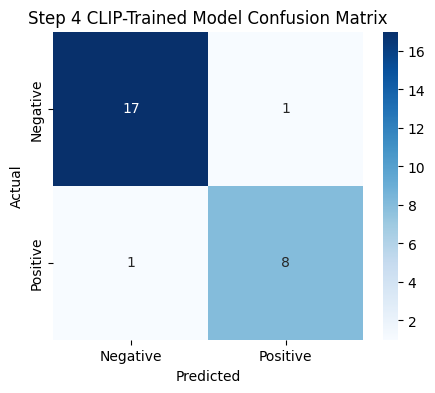

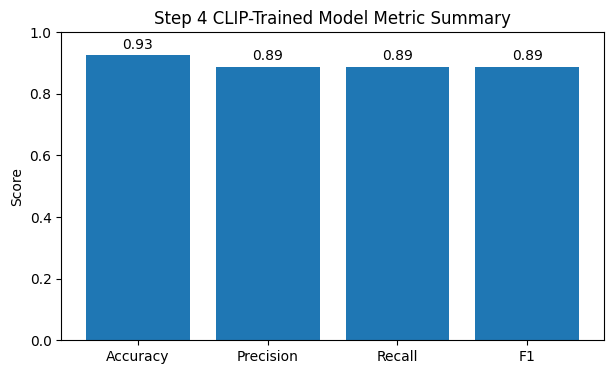

In [7]:
# TRAINED CLIP-BASED MODEL

import os
import json
import joblib
import clip
import torch
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression

# Setup
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

group_cols = ["compound", "sentence"]

clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)
clip_model.eval()

# Merge LLM Augmentation into Train
train_step4 = train_df.copy()
val_step4   = val_df.copy()
test_step4  = test_df.copy()

if "train_groups" in globals():
    train_step4 = train_step4.merge(
        train_groups[group_cols + ["sentence_aug", "idiom_gloss", "has_llm_aug"]],
        on=group_cols,
        how="left"
    )
    print("Merged Step 2 augmentation into Step 4.")
else:
    train_step4["sentence_aug"] = train_step4["sentence"]
    train_step4["idiom_gloss"] = ""
    train_step4["has_llm_aug"] = False
    print("Step 2 outputs not found. Using original sentence only.")

val_step4["sentence_aug"] = val_step4["sentence"]
val_step4["idiom_gloss"] = ""
val_step4["has_llm_aug"] = False

test_step4["sentence_aug"] = test_step4["sentence"]
test_step4["idiom_gloss"] = ""
test_step4["has_llm_aug"] = False

# Build Text Prompts
def safe_str(x):
    if pd.isna(x):
        return ""
    return str(x).strip()

def build_text_prompt(compound, sentence, gloss=""):
    compound = safe_str(compound)
    sentence = safe_str(sentence)
    gloss = safe_str(gloss)

    if gloss != "":
        return (
            f"The compound '{compound}' is used in this sentence: {sentence}. "
            f"Its meaning in context is: {gloss}."
        )
    else:
        return (
            f"The compound '{compound}' is used in this sentence: {sentence}. "
            f"Choose the image that matches the intended meaning in context."
        )

# Clip Encoders
@torch.no_grad()
def encode_texts(texts, batch_size=64):
    all_feats = []

    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        tokens = clip.tokenize(batch, truncate=True).to(device)
        feats = clip_model.encode_text(tokens)
        feats = feats / feats.norm(dim=-1, keepdim=True)
        all_feats.append(feats.cpu().numpy())

    return np.vstack(all_feats)

@torch.no_grad()
def encode_images_from_paths(image_paths, batch_size=64):
    all_feats = []

    for i in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[i:i+batch_size]
        batch_tensors = []

        for p in batch_paths:
            img = Image.open(p).convert("RGB")
            batch_tensors.append(clip_preprocess(img))

        batch_tensor = torch.stack(batch_tensors).to(device)
        feats = clip_model.encode_image(batch_tensor)
        feats = feats / feats.norm(dim=-1, keepdim=True)
        all_feats.append(feats.cpu().numpy())

    return np.vstack(all_feats)

# Feature Matrix
def build_clip_feature_matrix(df, image_dir, use_augmented_text=False):
    work = df.copy().reset_index(drop=True)

    if use_augmented_text:
        sentence_col = "sentence_aug"
    else:
        sentence_col = "sentence"

    work["text_prompt"] = work.apply(
        lambda r: build_text_prompt(
            r["compound"],
            r[sentence_col],
            r.get("idiom_gloss", "")
        ),
        axis=1
    )

    work["image_path"] = work["image_name"].apply(lambda x: os.path.join(image_dir, x))

    print(f"Encoding {len(work)} text prompts...")
    text_emb = encode_texts(work["text_prompt"].tolist())

    print(f"Encoding {len(work)} images...")
    img_emb = encode_images_from_paths(work["image_path"].tolist())

    cosine_sim = np.sum(text_emb * img_emb, axis=1, keepdims=True)
    abs_diff = np.abs(text_emb - img_emb)

    X = np.hstack([text_emb, img_emb, abs_diff, cosine_sim])

    return work, X

# Train Features
print("\nBuilding original training features...")
train_orig_df, X_train_orig = build_clip_feature_matrix(
    train_step4,
    train_img_dir,
    use_augmented_text=False
)

y_train_orig = train_orig_df["label"].values

# Augmented Train Features
use_aug = "train_groups" in globals()

if use_aug:
    train_aug_only = train_step4[train_step4["has_llm_aug"] == True].copy()

    print("\nBuilding augmented training features...")
    train_aug_df, X_train_aug = build_clip_feature_matrix(
        train_aug_only,
        train_img_dir,
        use_augmented_text=True
    )

    y_train_aug = train_aug_df["label"].values

    X_train = np.vstack([X_train_orig, X_train_aug])
    y_train = np.concatenate([y_train_orig, y_train_aug])

    print("Using original + augmented training data.")
    print("Original train rows :", len(train_orig_df))
    print("Augmented train rows:", len(train_aug_df))
    print("Final training rows :", len(y_train))
else:
    X_train = X_train_orig
    y_train = y_train_orig
    print("Using original training data only.")
    print("Final training rows:", len(y_train))

# Val/Test Features
print("\nBuilding validation features...")
val_feat_df, X_val = build_clip_feature_matrix(
    val_step4,
    val_img_dir,
    use_augmented_text=False
)
y_val = val_feat_df["label"].values

print("\nBuilding test features...")
test_feat_df, X_test = build_clip_feature_matrix(
    test_step4,
    test_img_dir,
    use_augmented_text=False
)
y_test = test_feat_df["label"].values

print("\nFeature shapes:")
print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

# Train Classifier
clf_clip = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    solver="liblinear"
)

clf_clip.fit(X_train, y_train)
print("Trained CLIP-based classifier.")

# Checkpoints
ckpt_dir = os.path.join(fpath, "checkpoints_clip_trained_model")
os.makedirs(ckpt_dir, exist_ok=True)

joblib.dump(clf_clip, os.path.join(ckpt_dir, "clip_logreg_model.joblib"))

config = {
    "clip_model_name": "ViT-B/32",
    "feature_definition": "[text_emb, image_emb, abs(text-image), cosine_similarity]",
    "uses_step2_augmentation": bool(use_aug),
    "group_cols": group_cols
}

with open(os.path.join(ckpt_dir, "clip_model_config.json"), "w") as f:
    json.dump(config, f, indent=2)

print("Saved checkpoints to:", ckpt_dir)
print(os.listdir(ckpt_dir))

# Predict Probabilities
train_probs = clf_clip.predict_proba(X_train_orig)[:, 1]
val_probs   = clf_clip.predict_proba(X_val)[:, 1]
test_probs  = clf_clip.predict_proba(X_test)[:, 1]

# Group IDs
train_eval_df = train_orig_df.copy()
val_eval_df   = val_feat_df.copy()
test_eval_df  = test_feat_df.copy()

train_eval_df["group_id"] = train_eval_df.groupby(group_cols).ngroup()
val_eval_df["group_id"]   = val_eval_df.groupby(group_cols).ngroup()
test_eval_df["group_id"]  = test_eval_df.groupby(group_cols).ngroup()

# Rank Within Groups
def rank_predictions(df, probs, score_col="score"):
    out = df.copy().reset_index(drop=True)
    out[score_col] = probs
    out["prediction"] = 0

    for gid, group in out.groupby("group_id"):
        idxs = group.index.tolist()
        scores = group[score_col].values
        best_idx = idxs[np.argmax(scores)]
        out.loc[best_idx, "prediction"] = 1

    return out

train_pred_clip = rank_predictions(train_eval_df, train_probs, score_col="score")
val_pred_clip   = rank_predictions(val_eval_df, val_probs, score_col="score")
test_pred_clip  = rank_predictions(test_eval_df, test_probs, score_col="score")

# Evaluate
def evaluate_predictions(df, group_cols, name="SET"):
    from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

    acc  = accuracy_score(df["label"], df["prediction"])
    prec = precision_score(df["label"], df["prediction"], zero_division=0)
    rec  = recall_score(df["label"], df["prediction"], zero_division=0)
    f1   = f1_score(df["label"], df["prediction"], zero_division=0)

    group_correct = df.groupby(group_cols).apply(
        lambda g: int(g.loc[g["prediction"].idxmax(), "label"] == 1)
    )
    group_acc = group_correct.mean()

    print(f"\n===== {name} RESULTS =====")
    print(f"Row Accuracy   : {acc:.4f}")
    print(f"Precision      : {prec:.4f}")
    print(f"Recall         : {rec:.4f}")
    print(f"F1 Score       : {f1:.4f}")
    print(f"Group Accuracy : {group_acc:.4f}")

    print("\nClassification report:")
    print(classification_report(df["label"], df["prediction"], digits=4, zero_division=0))

    return {
        "row_accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "group_accuracy": group_acc
    }

train_metrics_clip = evaluate_predictions(train_pred_clip, group_cols, name="TRAIN CLIP-TRAINED")
val_metrics_clip   = evaluate_predictions(val_pred_clip, group_cols, name="VAL CLIP-TRAINED")
test_metrics_clip  = evaluate_predictions(test_pred_clip, group_cols, name="TEST CLIP-TRAINED")

print("\n===== FINAL STEP 4 RESULTS =====")
print("Train:", train_metrics_clip)
print("Val  :", val_metrics_clip)
print("Test :", test_metrics_clip)

# Examples
def show_examples_clip(df_pred, n_groups=3):
    shown = 0
    for gid, group in df_pred.groupby("group_id", sort=True):
        if shown >= n_groups:
            break

        group = group.sort_values("score", ascending=False)

        print("\n" + "="*100)
        print("Compound:", group.iloc[0]["compound"])
        print("Sentence:", group.iloc[0]["sentence"])
        print("="*100)

        display(group[["image_name", "label", "score", "prediction"]])
        shown += 1

show_examples_clip(test_pred_clip, n_groups=3)

# PLots
def plot_confusion_and_metrics(df_pred, title="CLIP-Trained Model"):
    from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
    import matplotlib.pyplot as plt
    import seaborn as sns
    import pandas as pd

    metrics = {
        "Accuracy": accuracy_score(df_pred["label"], df_pred["prediction"]),
        "Precision": precision_score(df_pred["label"], df_pred["prediction"], zero_division=0),
        "Recall": recall_score(df_pred["label"], df_pred["prediction"], zero_division=0),
        "F1": f1_score(df_pred["label"], df_pred["prediction"], zero_division=0),
    }

    table = pd.DataFrame([metrics], index=[title])
    print("\n===== METRICS TABLE =====")
    display(table.round(4))

    cm = confusion_matrix(df_pred["label"], df_pred["prediction"])

    plt.figure(figsize=(5,4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )
    plt.title(f"{title} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    plt.figure(figsize=(7,4))
    bars = plt.bar(list(metrics.keys()), list(metrics.values()))
    plt.ylim(0,1)
    plt.title(f"{title} Metric Summary")
    plt.ylabel("Score")

    for b in bars:
        h = b.get_height()
        plt.text(b.get_x() + b.get_width()/2, h + 0.02, f"{h:.2f}", ha="center")

    plt.show()

plot_confusion_and_metrics(test_pred_clip, title="Step 4 CLIP-Trained Model")

## **Demo**

In [1]:
%pip install -q git+https://github.com/openai/CLIP.git
%pip install -q torch torchvision transformers sentencepiece accelerate
%pip install -q numpy pandas scikit-learn matplotlib seaborn pillow joblib tqdm

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.0 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Loaded checkpoint from: /content/drive/MyDrive/AAI/Task2/checkpoints_clip_trained_model
Config: {'clip_model_name': 'ViT-B/32', 'feature_definition': '[text_emb, image_emb, abs(text-image), cosine_similarity]', 'uses_step2_augmentation': True, 'group_cols': ['compound', 'sentence']}


100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 136MiB/s]


Enter compound: dirty money
Enter sentence: When dirty money disappears offshore, it becomes more difficult for governments to tackle corruption.

Upload exactly 3 images:


Saving 08230960409.png to 08230960409.png
Saving 46913780614.png to 46913780614.png
Saving 58491774071.png to 58491774071.png

===== DEMO RESULTS =====
Compound: dirty money
Sentence: When dirty money disappears offshore, it becomes more difficult for governments to tackle corruption.


,image_name,score,rank
0,08230960409.png,0.668942,1
1,46913780614.png,0.654555,2
2,58491774071.png,0.378824,3


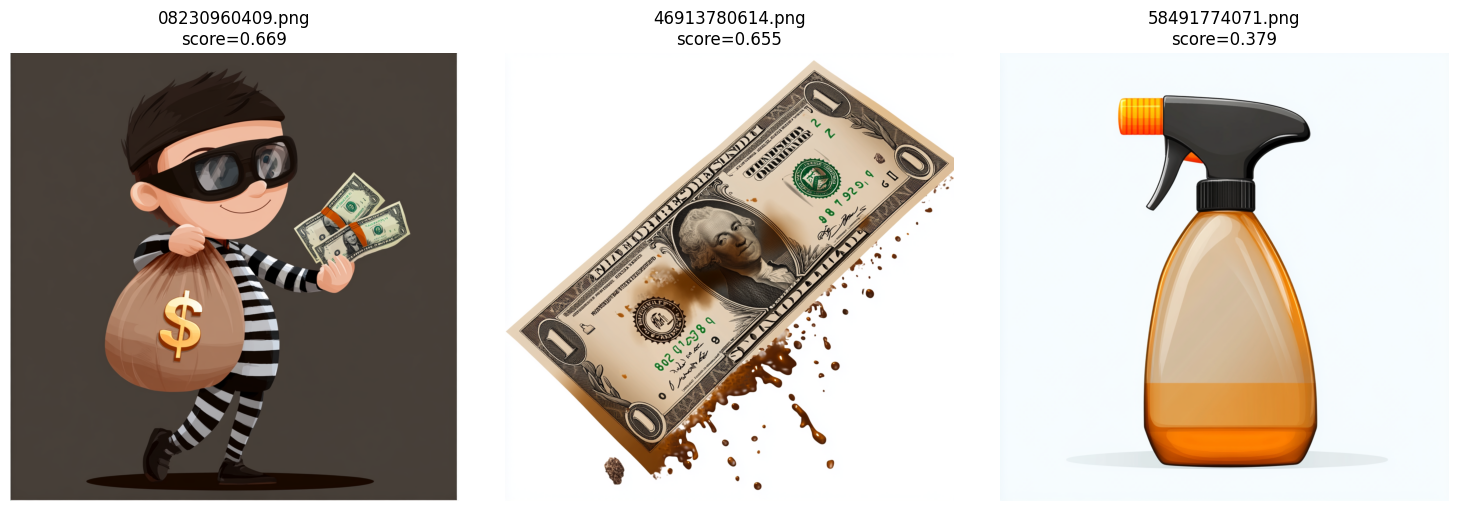


Predicted best image: 08230960409.png


In [3]:
# Demo

import os
import json
import joblib
import clip
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

# Checkpoint
fpath = "/content/drive/MyDrive/AAI/Task2/"
ckpt_dir = os.path.join(fpath, "checkpoints_clip_trained_model")

clf_clip = joblib.load(os.path.join(ckpt_dir, "clip_logreg_model.joblib"))

with open(os.path.join(ckpt_dir, "clip_model_config.json"), "r") as f:
    config = json.load(f)

print("Loaded checkpoint from:", ckpt_dir)
print("Config:", config)

# Load Clip
device = "cuda" if torch.cuda.is_available() else "cpu"
clip_model, clip_preprocess = clip.load(config["clip_model_name"], device=device)
clip_model.eval()

# Helpers
def safe_str(x):
    return "" if pd.isna(x) else str(x).strip()

def build_text_prompt(compound, sentence, gloss=""):
    compound = safe_str(compound)
    sentence = safe_str(sentence)
    gloss = safe_str(gloss)

    if gloss != "":
        return (
            f"The compound '{compound}' is used in this sentence: {sentence}. "
            f"Its meaning in context is: {gloss}."
        )
    else:
        return (
            f"The compound '{compound}' is used in this sentence: {sentence}. "
            f"Choose the image that matches the intended meaning in context."
        )

@torch.no_grad()
def encode_texts(texts, batch_size=32):
    all_feats = []

    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        tokens = clip.tokenize(batch, truncate=True).to(device)
        feats = clip_model.encode_text(tokens)
        feats = feats / feats.norm(dim=-1, keepdim=True)
        all_feats.append(feats.cpu().numpy())

    return np.vstack(all_feats)

@torch.no_grad()
def encode_images_from_paths(image_paths, batch_size=32):
    all_feats = []

    for i in range(0, len(image_paths), batch_size):
        batch_paths = image_paths[i:i+batch_size]
        batch_tensors = []

        for p in batch_paths:
            img = Image.open(p).convert("RGB")
            batch_tensors.append(clip_preprocess(img))

        batch_tensor = torch.stack(batch_tensors).to(device)
        feats = clip_model.encode_image(batch_tensor)
        feats = feats / feats.norm(dim=-1, keepdim=True)
        all_feats.append(feats.cpu().numpy())

    return np.vstack(all_feats)

def build_demo_feature_matrix(compound, sentence, image_paths):
    text_prompts = [build_text_prompt(compound, sentence) for _ in image_paths]
    text_emb = encode_texts(text_prompts)
    img_emb = encode_images_from_paths(image_paths)

    cosine_sim = np.sum(text_emb * img_emb, axis=1, keepdims=True)
    abs_diff = np.abs(text_emb - img_emb)

    X = np.hstack([text_emb, img_emb, abs_diff, cosine_sim])
    return X

# Demo Functions
def run_checkpoint_demo():
    compound = input("Enter compound: ").strip()
    sentence = input("Enter sentence: ").strip()

    if compound == "" or sentence == "":
        raise ValueError("Compound and sentence must not be empty.")

    print("\nUpload exactly 3 images:")
    uploaded = files.upload()
    image_paths = list(uploaded.keys())

    if len(image_paths) != 3:
        raise ValueError(f"You uploaded {len(image_paths)} image(s). Please upload exactly 3 images.")

    X_demo = build_demo_feature_matrix(compound, sentence, image_paths)
    probs = clf_clip.predict_proba(X_demo)[:, 1]

    result_df = pd.DataFrame({
        "image_name": image_paths,
        "score": probs
    }).sort_values("score", ascending=False).reset_index(drop=True)

    result_df["rank"] = range(1, len(result_df) + 1)

    print("\n===== DEMO RESULTS =====")
    print("Compound:", compound)
    print("Sentence:", sentence)
    display(result_df)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (_, row) in zip(axes, result_df.iterrows()):
        img = Image.open(row["image_name"]).convert("RGB")
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(f"{os.path.basename(row['image_name'])}\nscore={row['score']:.3f}")

    plt.tight_layout()
    plt.show()

    print("\nPredicted best image:", result_df.iloc[0]["image_name"])

# Run Demo
run_checkpoint_demo()